In [11]:
%matplotlib inline
import random
import torch
from d2l import torch as d2l

In [12]:
def synthetic_data(w, b, num_example):
    ''' y = wx+b '''
    X = torch.normal(0,1, (num_example, len(w)))
    y = torch.matmul(X,w)+b
    y += torch.normal(0, 0.01, y.shape)
    return X, y.reshape(-1,1)

In [13]:
true_w = torch.tensor([2, -3.4])
true_b = 4.2
features, labels = synthetic_data(true_w,true_b, 1000)

In [14]:
print('features:', features[0],'\nlabel:', labels[0])

features: tensor([-0.8727, -1.7871]) 
label: tensor([8.5134])


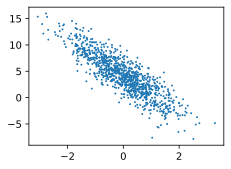

In [15]:
d2l.set_figsize()
d2l.plt.scatter(features[:,1].detach().numpy(), labels.detach().numpy(), 1)

In [16]:
def data_iter(batch_size, features, labels):
    num_example = len(features)
    ind = list(range(num_example))
    random.shuffle(ind)
    for i in range(0, num_example, batch_size):
        batch_ind = torch.tensor(ind[i:min(i+batch_size, num_example)])
        yield features[batch_ind],labels[batch_ind]

In [17]:
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break

tensor([[-0.0427, -0.1535],
        [-0.0884, -0.3531],
        [ 0.5197,  0.4288],
        [-1.5706, -1.0490],
        [ 1.4156, -0.1137],
        [-0.0114,  0.0810],
        [-0.5337, -1.4794],
        [ 0.4741,  1.2817],
        [ 0.0921,  0.1465],
        [ 0.4524,  0.3648]]) 
 tensor([[4.6093],
        [5.2278],
        [3.7629],
        [4.6303],
        [7.4193],
        [3.9050],
        [8.1666],
        [0.7749],
        [3.8941],
        [3.8658]])


In [18]:
w = torch.normal(0, 0.01, size=(2,1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

In [27]:
def linereg(X, w, b):
    return torch.matmul(X, w)+b

In [28]:
def squard_loss(y_hat, y):
    return (y_hat-y.reshape(y_hat.shape))**2 /2 

In [29]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr*param.grad/batch_size
            param.grad.zero_()

In [30]:
lr = 0.03
num_epochs = 3
net = linereg
loss = squard_loss

In [32]:
for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)
        l.sum().backward()
        sgd([w,b], lr, batch_size)
    with torch.no_grad():
        train_l = loss(net(features, w, b), labels)
        print(f'epoch: {epoch}, loss: {float(train_l.mean()):f}')

epoch: 0, loss: 0.000135
epoch: 1, loss: 0.000050
epoch: 2, loss: 0.000050
